# 02 — Préparation des données et feature engineering

**Projet 6 OpenClassrooms — Modèle de scoring crédit « Prêt à dépenser »**

**Objectif** : produire un jeu de données **propre, fusionné et enrichi**, avec une ligne par client, prêt pour l'entraînement (résultat attendu de l'étape 1).

**Méthode** : on s'appuie sur le kernel Kaggle [LightGBM with Simple Features](https://www.kaggle.com/code/jsaguiar/lightgbm-with-simple-features/script) (jsaguiar), comme le suggère Michaël. Conformément à la consigne, il a été **analysé et adapté** : le code est rangé dans `src/feature_engineering_functions.py`, sur le modèle des modules de fonctions des screencasts du cours (`feature_engineering_functions`, `data_processing_functions`, `settings.py`).

### Ce que fait le kernel, bloc par bloc

| Bloc | Table(s) | Transformations | Préfixe des features |
|---|---|---|---|
| Demande actuelle | `application_train/test` | Encodage binaire et one-hot, anomalie `DAYS_EMPLOYED`, 5 ratios financiers | — |
| Bureau de crédit | `bureau` + `bureau_balance` | Agrégation en 2 niveaux (mois → crédit → client), focus crédits actifs / clôturés | `BURO_`, `ACTIVE_`, `CLOSED_` |
| Demandes passées | `previous_application` | Ratio demandé / accordé, focus demandes acceptées / refusées | `PREV_`, `APPROVED_`, `REFUSED_` |
| Soldes POS / cash | `POS_CASH_balance` | Retards (`SK_DPD`), statut des contrats | `POS_` |
| Remboursements | `installments_payments` | Jours de retard / d'avance, part payée, écart au montant dû | `INSTAL_` |
| Cartes de crédit | `credit_card_balance` | min / max / moyenne / somme / variance de toutes les colonnes | `CC_` |

### Adaptations apportées au kernel
1. **Compatibilité pandas ≥ 2** : `DataFrame.append` a disparu → `pd.concat`.
2. **Suppression de la colonne parasite `index`** créée par `reset_index()` dans le kernel : sinon, le modèle apprendrait l'ordre des lignes dans le fichier.
3. **Encodage binaire explicite** (`F → 0`, `M → 1`, `N → 0`, `Y → 1`) au lieu de `pd.factorize`, dont le codage dépend de l'ordre d'apparition des valeurs : indispensable pour que l'explicabilité (SHAP) soit lisible par un chargé d'études.
4. **Indicateur `DAYS_EMPLOYED_ANOM`** (idée du kernel *Gentle Introduction*, voir notebook 01).
5. **Retards DPD/DBD vectorisés** (`clip`) au lieu d'un `apply` ligne à ligne sur 13,6 millions de lignes ; les `NaN` restent des `NaN` au lieu de devenir 0.
6. **Gestion mémoire (8 Go de RAM)** : float32, tables chargées une par une puis libérées.
7. **Nettoyage final** : infinis → `NaN` (divisions par 0 dans les ratios) ; noms de colonnes sans caractères spéciaux (LightGBM les refuse).
8. **Jeu de test (holdout) mis de côté** et filtrage des features calculé **uniquement sur le jeu d'entraînement** (anti fuite de données).

In [1]:
# -------------------------- Imports --------------------------
import sys

sys.path.append("..")

import gc
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

sns.set()

from src.settings import (
    FEATURES_USED_FILE,
    FIGURES_PATH,
    ID_COLUMN,
    NEW_CLIENTS_FILE,
    PROCESSED_DATA_PATH,
    TARGET,
    TEST_FILE,
    TEST_SIZE,
    TRAIN_FILE,
    random_state,
)
from src.data_processing_functions import (
    clean_column_names,
    missing_values_table,
    replace_infinite_values,
)
from src.feature_engineering_functions import build_features

PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

## 1. Construction des features (agrégations + jointures)

**Pourquoi agréger ?** Un modèle de classification attend **une ligne par individu**. Or un client a en moyenne 5 crédits au bureau, 5 demandes passées, environ 40 échéances de remboursement... On résume donc chaque historique par des statistiques (min, max, moyenne, somme, variance) : par exemple `INSTAL_DPD_MEAN` est le **nombre moyen de jours de retard** du client sur ses remboursements passés.

Les jointures sont faites **à gauche** sur `SK_ID_CURR`, et la fonction **vérifie après chaque jointure que le nombre de lignes n'a pas changé** (point de vigilance de la consigne : « fusionner sans gérer les duplications ou pertes de lignes »).

> Durée : quelques minutes (environ 60 millions de lignes à agréger).

In [2]:
start = time.time()
df = build_features()
print(f"\nDurée : {time.time() - start:.0f} s | Mémoire : {df.memory_usage().sum() / 1024**2:.0f} Mo")

application_train.csv : 307,511 lignes x 122 colonnes
application_test.csv : 48,744 lignes x 121 colonnes


Lignes supprimées (CODE_GENDER = XNA) : 4


Table principale : (356251, 248)


bureau.csv : 1,716,428 lignes x 17 colonnes


bureau_balance.csv : 27,299,925 lignes x 3 colonnes


...

+ pos_cash                 18 features | clients couverts : 94.7%


installments_payments.csv : 13,605,401 lignes x 8 colonnes


+ installments             26 features | clients couverts : 95.3%


credit_card_balance.csv : 3,840,312 lignes x 23 colonnes


+ credit_card             141 features | clients couverts : 29.1%
Dataset final : (356251, 798)

Durée : 25 s | Mémoire : 910 Mo


## 2. Nettoyage final et contrôles qualité

In [3]:
df = replace_infinite_values(df)
df = clean_column_names(df)

assert df[ID_COLUMN].is_unique, "SK_ID_CURR doit rester unique"
assert "index" not in df.columns
print(f"Dimensions : {df.shape}")
print(f"Doublons de lignes : {df.duplicated().sum()}")
print("Types :", df.dtypes.astype(str).value_counts().to_dict())

61 valeurs infinies remplacées par NaN
Dimensions : (356251, 798)


Doublons de lignes : 0
Types : {'float32': 622, 'uint8': 137, 'int8': 36, 'int16': 2, 'int32': 1}


## 3. Séparation des jeux de données

On distingue trois jeux :

| Jeu | Origine | Usage |
|---|---|---|
| **train** (80 %) | `application_train` | Validation croisée, optimisation des hyperparamètres et du seuil |
| **test** (20 %) | `application_train` | **Évaluation finale uniquement**, jamais utilisé pour faire un choix |
| **new_clients** | `application_test` (sans cible) | Simulation de « nouveaux clients » : serving MLflow, API, suivi de dérive |

**Pourquoi un test mis de côté alors qu'on fera de la validation croisée ?** La validation croisée sert à **choisir** (modèle, hyperparamètres, seuil). Chaque choix « consomme » un peu de l'information des plis de validation, donc le score de CV du meilleur modèle est optimiste. Le jeu de test, jamais vu, donne une estimation **non biaisée** de la performance en production (cours *Maîtriser l'apprentissage supervisé* : séparation Train / Validation / Test).

Le découpage est **stratifié** sur la cible pour garder 8,07 % de défauts dans chaque jeu.

In [4]:
labelled = df[df[TARGET].notna()].copy()
new_clients = df[df[TARGET].isna()].drop(columns=[TARGET]).copy()
labelled[TARGET] = labelled[TARGET].astype(np.int8)
del df
gc.collect()

train, test = train_test_split(
    labelled, test_size=TEST_SIZE, stratify=labelled[TARGET], random_state=random_state
)
del labelled
gc.collect()

for name, data in [("train", train), ("test", test)]:
    print(f"{name:<12} {data.shape[0]:>7,} lignes | taux de défaut : {data[TARGET].mean():.2%}")
print(f"{'new_clients':<12} {new_clients.shape[0]:>7,} lignes | cible inconnue")

train        246,005 lignes | taux de défaut : 8.07%
test          61,502 lignes | taux de défaut : 8.07%
new_clients   48,744 lignes | cible inconnue


## 4. Sélection des features (calculée sur le train uniquement)

Le kernel produit plus de 750 features. On applique trois filtres simples et justifiables. La sélection par importance se fera à l'étape de modélisation, comme dans le screencast `p3_c4_mlflow.py` (`get_features_most_importance` : on garde les features qui cumulent 80 % de l'importance).

### 4.1 Features constantes
Une colonne qui ne prend qu'une seule valeur n'apporte aucune information.

In [5]:
candidate_features = [c for c in train.columns if c not in (ID_COLUMN, TARGET)]
n_unique = train[candidate_features].nunique(dropna=False)
constant_features = n_unique[n_unique <= 1].index.tolist()
print(f"{len(constant_features)} features constantes supprimées :")
print(constant_features)
features = [c for c in candidate_features if c not in constant_features]

0 features constantes supprimées :
[]


### 4.2 Valeurs manquantes : on mesure, on ne supprime pas

616 features sur 796 ont des valeurs manquantes


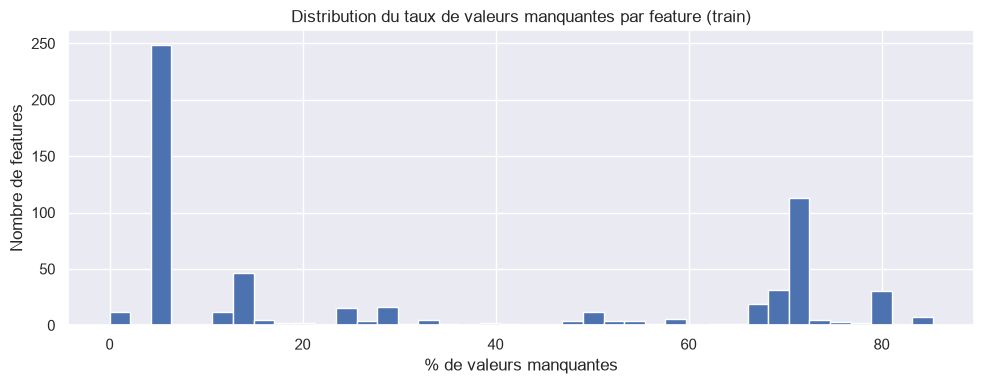

,nb_manquants,pct_manquants,dtype
REFUSED_RATE_DOWN_PAYMENT_MEAN,209866,85.309648,float32
REFUSED_RATE_DOWN_PAYMENT_MAX,209866,85.309648,float32
REFUSED_RATE_DOWN_PAYMENT_MIN,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MEAN,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MAX,209866,85.309648,float32
REFUSED_AMT_DOWN_PAYMENT_MIN,209866,85.309648,float32
REFUSED_APP_CREDIT_PERC_VAR,206734,84.036503,float32
CC_AMT_PAYMENT_CURRENT_VAR,197451,80.263003,float32
CC_AMT_DRAWINGS_OTHER_CURRENT_VAR,197378,80.233329,float32
CC_AMT_DRAWINGS_ATM_CURRENT_VAR,197378,80.233329,float32


In [6]:
missing_features = missing_values_table(train[features])
print(f"{len(missing_features)} features sur {len(features)} ont des valeurs manquantes")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(missing_features["pct_manquants"], bins=40)
ax.set_xlabel("% de valeurs manquantes")
ax.set_ylabel("Nombre de features")
ax.set_title("Distribution du taux de valeurs manquantes par feature (train)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_missing_rate_distribution.png", dpi=100)
plt.show()

missing_features.head(10)

**Pourquoi on ne supprime pas ces colonnes** : les taux de manquants élevés viennent surtout des **agrégats des tables à faible couverture** (cartes de crédit : 28 % des clients ; demandes refusées : une partie seulement des clients). Pour ces features, `NaN` signifie « le client n'a pas ce type d'historique », ce qui est une information en soi. LightGBM l'exploite directement ; pour les autres modèles, l'imputation sera faite dans le `Pipeline` de validation croisée.

### 4.3 Features redondantes (corrélation > 0,95)

On reprend la démarche de `p1_c3_correlations.py` : retirer les variables quasi identiques à une autre. Par exemple, `AMT_GOODS_PRICE` (prix du bien) et `AMT_CREDIT` (montant du crédit), ou les versions `_AVG`, `_MEDI` et `_MODE` d'une même caractéristique du logement.

Avec plus de 700 features, on automatise : pour chaque paire corrélée à plus de 0,95 (en valeur absolue), on **garde la feature la plus complète** (le moins de `NaN`). La corrélation est calculée sur un échantillon de 30 000 clients du train pour limiter le temps de calcul.

In [7]:
CORRELATION_THRESHOLD = 0.95

sample = train[features].sample(30_000, random_state=random_state)
start = time.time()
corr_matrix = sample.corr(min_periods=1000).abs()
print(f"Matrice de corrélation {corr_matrix.shape} calculée en {time.time() - start:.0f} s")

# On parcourt les features de la plus complète à la moins complète
missing_rate = train[features].isna().mean()
ordered_features = missing_rate.sort_values(kind="stable").index.tolist()

kept, redundant_pairs = [], []
for feature in ordered_features:
    correlated_with_kept = corr_matrix.loc[feature, kept]
    correlated_with_kept = correlated_with_kept[correlated_with_kept > CORRELATION_THRESHOLD]
    if correlated_with_kept.empty:
        kept.append(feature)
    else:
        redundant_pairs.append((feature, correlated_with_kept.idxmax(), correlated_with_kept.max()))

redundant = pd.DataFrame(redundant_pairs, columns=["feature_supprimee", "redondante_avec", "corr_abs"])
print(f"{len(redundant)} features redondantes supprimées, {len(kept)} conservées")
redundant.head(15)

Matrice de corrélation (796, 796) calculée en 22 s


137 features redondantes supprimées, 659 conservées


,feature_supprimee,redondante_avec,corr_abs
0,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,0.954497
1,NAME_CONTRACT_TYPE_Revolving_loans,NAME_CONTRACT_TYPE_Cash_loans,1.000000
2,NAME_INCOME_TYPE_Pensioner,FLAG_EMP_PHONE,0.999437
3,ORGANIZATION_TYPE_XNA,FLAG_EMP_PHONE,0.999887
4,DAYS_EMPLOYED_ANOM,FLAG_EMP_PHONE,0.999887
5,AMT_GOODS_PRICE,AMT_CREDIT,0.986932
6,OBS_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,0.998364
7,INSTAL_AMT_PAYMENT_SUM,INSTAL_AMT_INSTALMENT_SUM,0.982154
8,INSTAL_AMT_PAYMENT_MAX,INSTAL_AMT_INSTALMENT_MAX,0.999221
9,INSTAL_AMT_PAYMENT_MEAN,INSTAL_AMT_INSTALMENT_MEAN,0.974507


**Lecture des redondances**
- Beaucoup de redondances sont **mécaniques** : les deux modalités d'une variable binaire après one-hot (`Cash_loans` / `Revolving_loans`), ou montant demandé et montant accordé (`PREV_AMT_APPLICATION` / `PREV_AMT_CREDIT`), échéance due et payée (`INSTAL_AMT_INSTALMENT` / `INSTAL_AMT_PAYMENT`).
- `DAYS_EMPLOYED_ANOM`, `NAME_INCOME_TYPE_Pensioner` et `ORGANIZATION_TYPE_XNA` sont retirées car **quasiment identiques à `FLAG_EMP_PHONE`** (corrélation 0,9999) : un retraité n'a ni employeur ni téléphone professionnel. **L'information « retraité / sans emploi » est donc conservée** via `FLAG_EMP_PHONE` (= 1 − `DAYS_EMPLOYED_ANOM`).

In [8]:
features_used = [f for f in features if f in set(kept)]  # ordre d'origine des colonnes
del sample, corr_matrix
gc.collect()
print(f"Features avant filtrage : {len(candidate_features)}")
print(f"  - constantes          : {len(constant_features)}")
print(f"  - redondantes         : {len(redundant)}")
print(f"Features retenues       : {len(features_used)}")

Features avant filtrage : 796
  - constantes          : 0
  - redondantes         : 137
Features retenues       : 659


## 5. Validation de la qualité des features

Avant de modéliser, on vérifie que les features construites portent bien un signal. Mesure simple et robuste au déséquilibre : l'**AUC univariée**, c'est-à-dire l'AUC obtenue en utilisant **une seule feature comme score**.
- AUC = 0,5 : aucun pouvoir discriminant (hasard) ;
- AUC éloignée de 0,5 (au-dessus ou en dessous) : la feature sépare bons et mauvais clients. On affiche donc `max(AUC, 1 − AUC)`.

Calcul sur le train uniquement (échantillon de 60 000 clients), en ignorant les `NaN` de chaque feature.

In [9]:
auc_sample = train.sample(60_000, random_state=random_state)
univariate = []
for feature in features_used:
    values = auc_sample[feature]
    mask = values.notna()
    y_feature = auc_sample.loc[mask, TARGET]
    if mask.sum() < 1000 or y_feature.nunique() < 2 or values[mask].nunique() < 2:
        continue
    auc = roc_auc_score(y_feature, values[mask])
    univariate.append({
        "feature": feature,
        "auc_univariee": max(auc, 1 - auc),
        "sens": "risque ↑ quand valeur ↑" if auc > 0.5 else "risque ↓ quand valeur ↑",
        "pct_renseigne": round(100 * mask.mean(), 1),
    })
univariate = pd.DataFrame(univariate).sort_values("auc_univariee", ascending=False)
univariate.head(25).reset_index(drop=True)

,feature,auc_univariee,sens,pct_renseigne
0,EXT_SOURCE_3,0.680764,risque ↓ quand valeur ↑,80.1
1,EXT_SOURCE_1,0.663740,risque ↓ quand valeur ↑,43.7
2,EXT_SOURCE_2,0.656224,risque ↓ quand valeur ↑,99.8
3,CC_CNT_DRAWINGS_CURRENT_VAR,0.635358,risque ↑ quand valeur ↑,27.8
4,CC_CNT_DRAWINGS_CURRENT_MEAN,0.632829,risque ↑ quand valeur ↑,28.0
5,CC_CNT_DRAWINGS_CURRENT_MAX,0.625948,risque ↑ quand valeur ↑,28.0
6,CC_AMT_DRAWINGS_CURRENT_MEAN,0.614695,risque ↑ quand valeur ↑,28.0
7,CC_AMT_BALANCE_MEAN,0.611642,risque ↑ quand valeur ↑,28.0
8,CC_CNT_DRAWINGS_CURRENT_SUM,0.608633,risque ↑ quand valeur ↑,28.0
9,CC_AMT_DRAWINGS_CURRENT_VAR,0.608291,risque ↑ quand valeur ↑,27.8


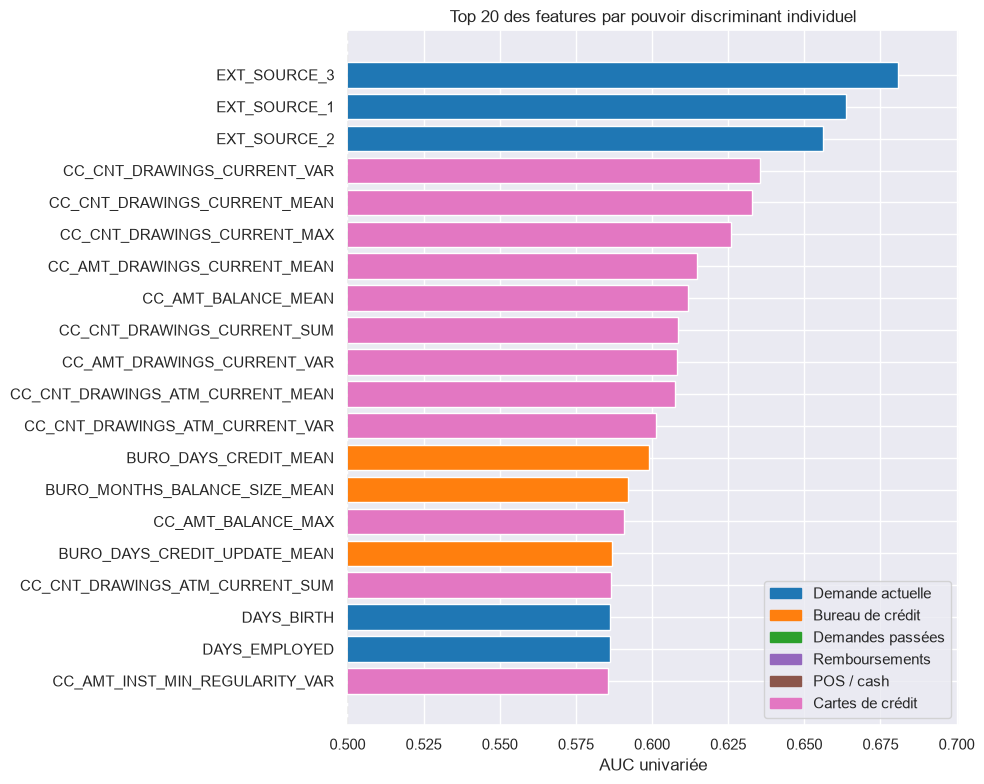

Parmi les 50 features les plus discriminantes, 44 sont des features créées


In [10]:
top = univariate.head(20).iloc[::-1]
source_colors = {
    "BURO": "tab:orange", "ACTIVE": "tab:orange", "CLOSED": "tab:orange",
    "PREV": "tab:green", "APPROVED": "tab:green", "REFUSED": "tab:green",
    "INSTAL": "tab:purple", "POS": "tab:brown", "CC": "tab:pink",
}
colors = [source_colors.get(f.split("_")[0], "tab:blue") for f in top["feature"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top["feature"], top["auc_univariee"], color=colors)
ax.axvline(0.5, color="grey", linestyle="--")
ax.set_xlim(0.5, top["auc_univariee"].max() + 0.02)
ax.set_xlabel("AUC univariée")
ax.set_title("Top 20 des features par pouvoir discriminant individuel")
from matplotlib.patches import Patch
legend_items = [
    ("Demande actuelle", "tab:blue"), ("Bureau de crédit", "tab:orange"),
    ("Demandes passées", "tab:green"), ("Remboursements", "tab:purple"),
    ("POS / cash", "tab:brown"), ("Cartes de crédit", "tab:pink"),
]
ax.legend(handles=[Patch(color=c, label=l) for l, c in legend_items], loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_univariate_auc_top20.png", dpi=100)
plt.show()

created_prefixes = ("BURO_", "ACTIVE_", "CLOSED_", "PREV_", "APPROVED_", "REFUSED_",
                    "POS_", "INSTAL_", "CC_")
created_ratios = ("DAYS_EMPLOYED_PERC", "INCOME_CREDIT_PERC", "INCOME_PER_PERSON",
                  "ANNUITY_INCOME_PERC", "PAYMENT_RATE", "DAYS_EMPLOYED_ANOM")
n_created_top50 = sum(
    f.startswith(created_prefixes) or f in created_ratios for f in univariate.head(50)["feature"]
)
print(f"Parmi les 50 features les plus discriminantes, {n_created_top50} sont des features créées")

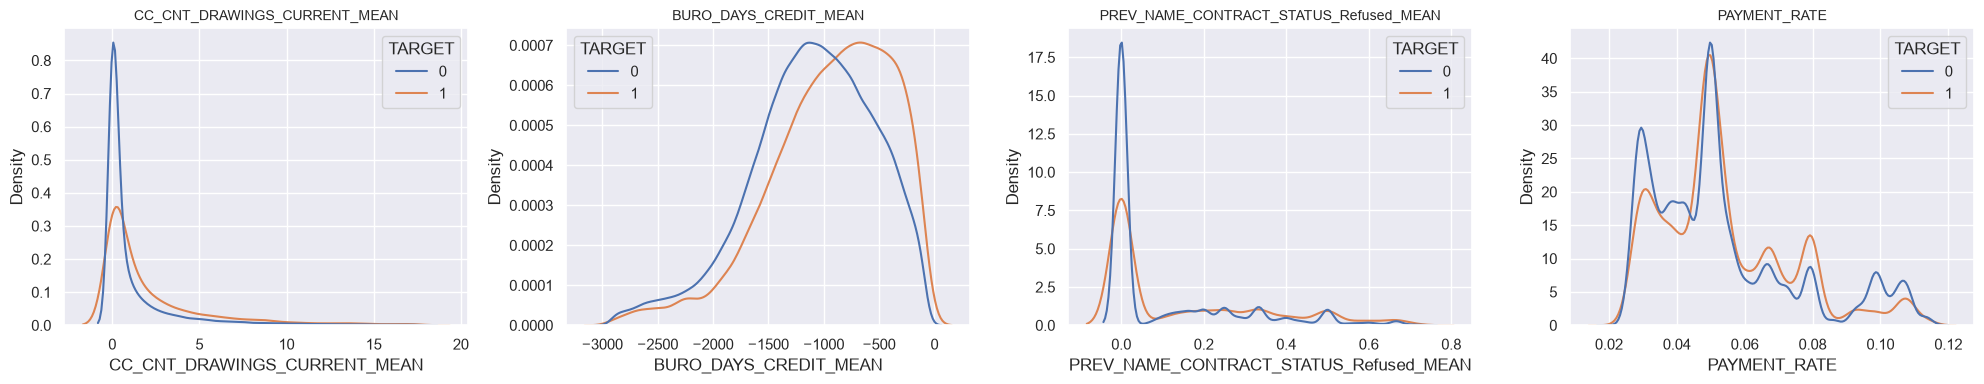

In [11]:
features_to_plot = ["CC_CNT_DRAWINGS_CURRENT_MEAN", "BURO_DAYS_CREDIT_MEAN",
                    "PREV_NAME_CONTRACT_STATUS_Refused_MEAN", "PAYMENT_RATE"]
features_to_plot = [f for f in features_to_plot if f in train.columns]

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(5 * len(features_to_plot), 4))
for ax, feature in zip(axes, features_to_plot):
    data = train[[feature, TARGET]].dropna()
    upper = data[feature].quantile(0.99)  # on coupe les 1 % extrêmes pour la lisibilité
    sns.kdeplot(data=data[data[feature] <= upper], x=feature, hue=TARGET,
                common_norm=False, ax=ax)
    ax.set_title(feature, fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_kde_engineered_features.png", dpi=100)
plt.show()

**Lecture**
- Les scores externes `EXT_SOURCE_*` restent en tête (AUC de 0,66 à 0,68), mais **la grande majorité des 50 features les plus discriminantes sont des features créées** par le feature engineering, ce qui valide l'intérêt des agrégations.
- Elles décrivent surtout deux comportements :
  - l'**usage intensif du crédit renouvelable** (`CC_CNT_DRAWINGS_*` : nombre de retraits ; `CC_AMT_BALANCE_*` : encours) : un client qui tire beaucoup sur sa carte signale une tension de trésorerie ;
  - l'**historique au bureau de crédit** : des crédits plus récents (`BURO_DAYS_CREDIT_MEAN` moins négatif) et une forte part de crédits encore actifs augmentent le risque.
- Les historiques de **refus** (`PREV_NAME_CONTRACT_STATUS_Refused_MEAN`) et de **retards de paiement** (`INSTAL_DPD_MEAN`) sont aussi discriminants (AUC d'environ 0,56) : c'est le principe de l'analyse crédit, selon lequel le comportement passé prédit le comportement futur.

**Deux limites de l'AUC univariée, à garder en tête**
1. **Biais de couverture** : l'AUC est calculée sur les clients renseignés. Pour les features `CC_` (environ 28 % des clients), elle mesure le pouvoir discriminant **parmi les détenteurs de carte**, pas sur l'ensemble.
2. **Elle ne capte que les relations monotones** : `PAYMENT_RATE` n'a qu'une AUC de 0,54, alors que le notebook 01 a montré un signal fort mais **non monotone** (le risque monte puis chute au dernier décile). C'est d'ailleurs l'une des features les plus importantes du kernel jsaguiar une fois exploitée par LightGBM. On ne sélectionnera donc **pas** les features sur ce critère : la sélection fine se fera sur l'importance mesurée **par le modèle** (étape 3).

Enfin, aucune feature isolée ne dépasse une AUC de 0,7 : la performance viendra de leur **combinaison**. En référence, le premier du challenge Kaggle atteint 0,80 à 0,82 ; au-delà, il faudra suspecter du surapprentissage ou une fuite de données (consigne de Michaël).

## 6. Sauvegarde

- Jeux de données au format **Parquet** (comme dans les screencasts) : format colonne compressé qui conserve les types et se lit 10 à 20 fois plus vite qu'un CSV.
- Liste des features retenues dans `features_used.json` (même logique que `features_used.json` dans `p1_c3_correlations.py`), **versionnée sur GitHub** : elle sera loggée dans MLflow avec chaque run, pour la traçabilité.

In [12]:
columns_to_save = [ID_COLUMN, TARGET] + features_used
train[columns_to_save].to_parquet(TRAIN_FILE, index=False)
test[columns_to_save].to_parquet(TEST_FILE, index=False)
new_clients[[ID_COLUMN] + features_used].to_parquet(NEW_CLIENTS_FILE, index=False)

with open(FEATURES_USED_FILE, "w") as f:
    json.dump(features_used, f, indent=2)

for path in [TRAIN_FILE, TEST_FILE, NEW_CLIENTS_FILE]:
    print(f"{path.name:<22} {path.stat().st_size / 1024**2:>6.0f} Mo")
print(f"{FEATURES_USED_FILE.name:<22} {len(features_used)} features")

train.parquet             118 Mo
test.parquet               31 Mo
new_clients.parquet        26 Mo
features_used.json     659 features


## 7. Bilan de l'étape 1

**Résultat** : un jeu de données propre, fusionné et enrichi, avec une ligne par client, découpé en train / test stratifiés, et une liste de features documentée.

**Fiche d'autoévaluation, étape 1**
- ✅ Données brutes explorées, formats identifiés, valeurs manquantes, doublons et jointures contrôlés (notebooks 01 et 02).
- ✅ Features pertinentes construites par agrégats et transformations (kernel jsaguiar adapté).
- ✅ Qualité des features validée par visualisations et statistiques (AUC univariée, distributions par classe).
- ✅ Déséquilibre des classes identifié (8,07 %) : stratification en place ; pondération et coût métier à l'étape de modélisation.
- ⏭️ Tester plusieurs modèles avec validation croisée et des métriques adaptées : **notebook 03**, avec tracking MLflow (étapes 2 et 3).

**Prochaine étape** : notebook `03_modelisation_mlflow.ipynb`
1. Fonction de **coût métier** (10 × FN + FP) et optimisation du seuil.
2. `DummyClassifier`, régression logistique, Random Forest, LightGBM, XGBoost, MLP en `StratifiedKFold`, avec gestion du déséquilibre.
3. Tracking MLflow (paramètres, métriques, modèles, tags), interface `mlflow ui`, puis model registry.